In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Loading the data

In [10]:
!unzip -q Inspec_dataset.zip -d /content/neu
path = "/content/neu"

In [11]:
import os

all_files = []
for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            all_files.append(os.path.join(root, f))

print("Total images:", len(all_files))
print("Examples:")
for f in all_files[:5]:
    print(" ", f)

Total images: 1800
Examples:
  /content/neu/NEU-DET/validation/images/scratches/scratches_242.jpg
  /content/neu/NEU-DET/validation/images/scratches/scratches_255.jpg
  /content/neu/NEU-DET/validation/images/scratches/scratches_290.jpg
  /content/neu/NEU-DET/validation/images/scratches/scratches_282.jpg
  /content/neu/NEU-DET/validation/images/scratches/scratches_292.jpg


In [12]:
# build a dataframe of every image path + its label
rows = []
for f in all_files:
    parts = f.split(os.sep)
    rows.append({
        "path": f,
        "label": parts[-2],
        "orig_split": "train" if "train" in parts else "validation"
    })

df = pd.DataFrame(rows)

EDA

In [13]:
df.head()

,path,label,orig_split
0,/content/neu/NEU-DET/validation/images/scratch...,scratches,validation
1,/content/neu/NEU-DET/validation/images/scratch...,scratches,validation
2,/content/neu/NEU-DET/validation/images/scratch...,scratches,validation
3,/content/neu/NEU-DET/validation/images/scratch...,scratches,validation
4,/content/neu/NEU-DET/validation/images/scratch...,scratches,validation


In [14]:
df.shape

(1800, 3)

In [15]:
df.isnull().sum()

,0
path,0
label,0
orig_split,0


In [16]:
df["label"].value_counts()  # are all 6 classes balanced?

,count
label,
scratches,300
rolled-in_scale,300
pitted_surface,300
inclusion,300
crazing,300
patches,300


In [17]:
df["orig_split"].value_counts()

,count
orig_split,
train,1440
validation,360


In [18]:
pd.crosstab(df["orig_split"], df["label"])  # images per class in the original train/validation folders

label,crazing,inclusion,patches,pitted_surface,rolled-in_scale,scratches
orig_split,,,,,,
train,240,240,240,240,240,240
validation,60,60,60,60,60,60


In [19]:
from PIL import Image  #library for opening images

classes = sorted(df["label"].unique())  # the 6 defect names, in alphabetical order
classes

['crazing',
 'inclusion',
 'patches',
 'pitted_surface',
 'rolled-in_scale',
 'scratches']

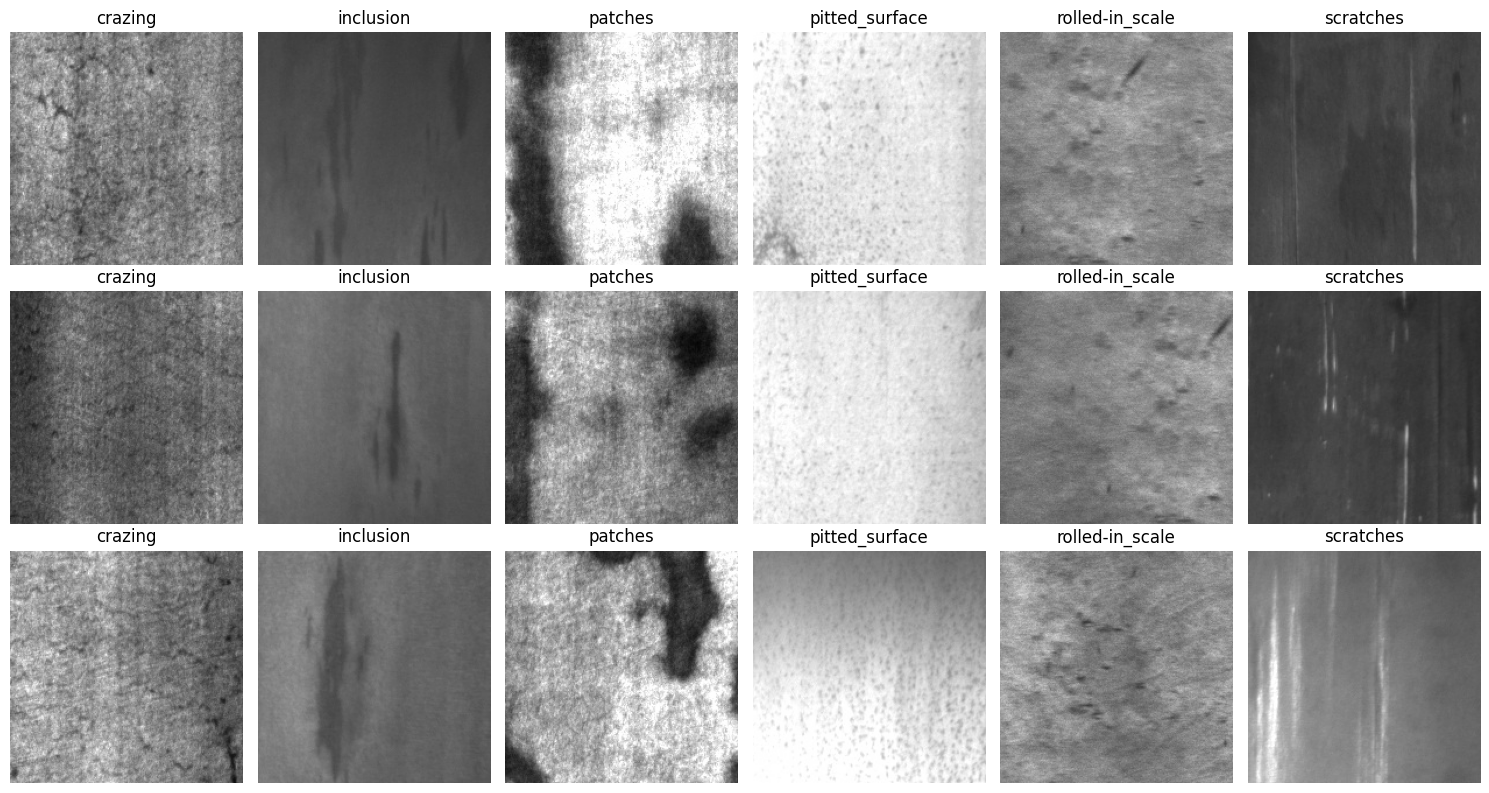

In [20]:
plt.figure(figsize=(15, 8))

for i, cls in enumerate(classes):
    # pick 3 random images of this defect type
    sample_paths = df[df["label"] == cls]["path"].sample(3, random_state=42)

    for j, p in enumerate(sample_paths):
        plt.subplot(3, 6, j*6 + i + 1)  # a grid of 3 rows x 6 columns, this picks which box to draw in
        img = Image.open(p)  # open the image from its address
        plt.imshow(img, cmap="gray")  # draw it in grayscale
        plt.title(cls)
        plt.axis("off")  # hide the axis numbers

plt.tight_layout()
plt.show()

In [21]:
sizes = []
for p in df["path"]:
    img = Image.open(p)
    sizes.append(img.size + (img.mode,))  # (width, height) plus the color mode

pd.Series(sizes).value_counts()

,count
"(200, 200, RGB)",1800


Train test validation split

In [22]:
from sklearn.model_selection import train_test_split
#70-15-15 split
train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=42)

val_df, test_df = train_test_split(temp_df, test_size=0.5,stratify=temp_df["label"], random_state=42)

print(train_df.shape, val_df.shape, test_df.shape)

(1260, 3) (270, 3) (270, 3)


In [23]:
# check that every split has the same class balance
pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "val": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts()
})

,train,val,test
label,,,
crazing,210,45,45
inclusion,210,45,45
patches,210,45,45
pitted_surface,210,45,45
rolled-in_scale,210,45,45
scratches,210,45,45


Data preprocessing

In [24]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical #one hot encoding

le = LabelEncoder()
le.fit(df["label"])  # learns the 6 class names and gives each one a number
class_names = list(le.classes_)
num_classes = len(class_names)
print(class_names)

['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [25]:
y_train = to_categorical(le.transform(train_df["label"]), num_classes)
y_val = to_categorical(le.transform(val_df["label"]), num_classes)
y_test = to_categorical(le.transform(test_df["label"]), num_classes)

y_train.shape

(1260, 6)

In [26]:
import tensorflow as tf

IMG_SIZE = 224  # pretrained models expect 224x224 images
BATCH_SIZE = 32

def load_image(path, label):
    img = tf.io.read_file(path)  # read the raw file from disk
    img = tf.image.decode_jpeg(img, channels=3)  # turn the file into a pixel array (3 color channels)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))  # 200x200 -> 224x224
    return img, label

In [27]:
def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))  # pairs each path with its label
    if shuffle:
        ds = ds.shuffle(len(paths), seed=42)  # mix the order (only for training)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)  # run load_image on every item
    ds = ds.batch(BATCH_SIZE)  # group images into batches of 32
    ds = ds.prefetch(tf.data.AUTOTUNE)  # load the next batch while the model trains on this one
    return ds

In [28]:
train_ds = make_dataset(train_df["path"].values, y_train, shuffle=True)
val_ds = make_dataset(val_df["path"].values, y_val)
test_ds = make_dataset(test_df["path"].values, y_test)